<a href="https://colab.research.google.com/github/nuruyar/ai_master_computervision/blob/main/lab_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**13/10/2026  LAB_3**

In [ ]:
from PIL import Image
from pylab import *
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.ndimage as snd
from scipy.ndimage import *
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


(417, 360)
2.0
255.0


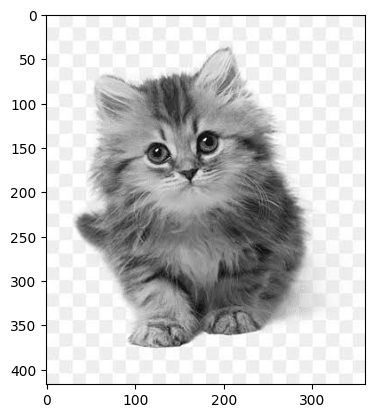

In [ ]:
import os
path = "/content/drive/MyDrive/Colab Notebooks/Bilgisayarla Görme"
im = np.array(Image.open(path+"/kedi.jpeg"))
im_gray = np.array(Image.open(path+"/kedi.jpeg").convert('L'), np.float64)
print(im_gray.shape)
print(im_gray.min())
print(im_gray.max())


imgplot = plt.imshow(im_gray, cmap='gray')
plt.show()


**CORRELATION AND CONVOLUTION**

<class 'numpy.ndarray'>


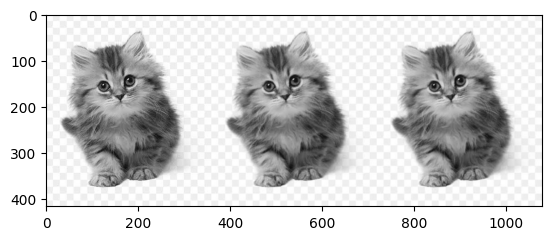

In [ ]:
filt = np.array([[0,1,0],[1,1,1],[0,1,0]])
filt= 1/5 * filt
print(type(filt))
im_cor = snd.correlate(im_gray, filt, mode='nearest')
im_conv = snd.convolve(im_gray, filt, mode='nearest')
im_list = np.concatenate((im_gray, im_cor, im_conv), axis=1)
imgplot=plt.imshow(im_list, cmap='gray')
plt.show()



**GAUSSIAN FILTERING**

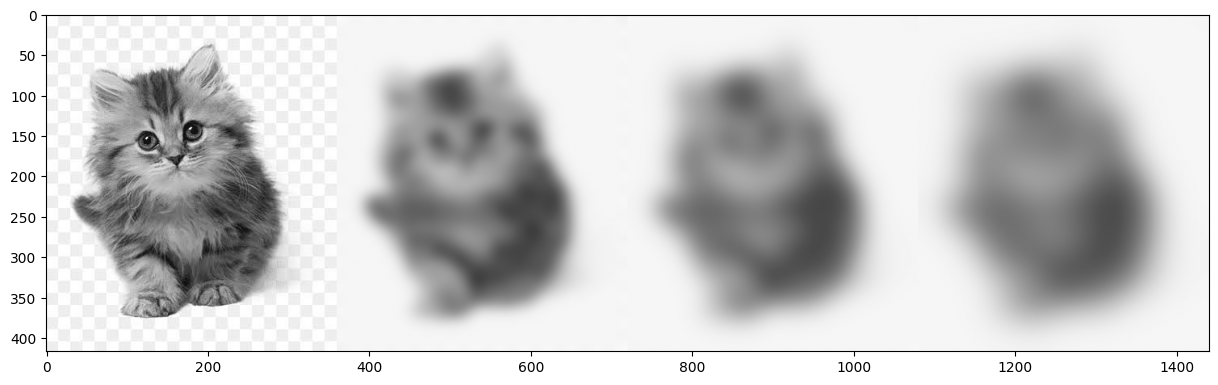

In [ ]:
sc = 3
im3 =gaussian_filter(im_gray, sc*3)
im5 =gaussian_filter(im_gray, sc*5)
im7 =gaussian_filter(im_gray, sc*7)

im_ss = np.concatenate((im_gray, im3, im5, im7),axis=1)

figure(figsize=(15,10))

imgplot = plt.imshow(np.uint8(im_ss), cmap = 'gray')
plt.show()


**1 D GAUSSIAN FILTER**

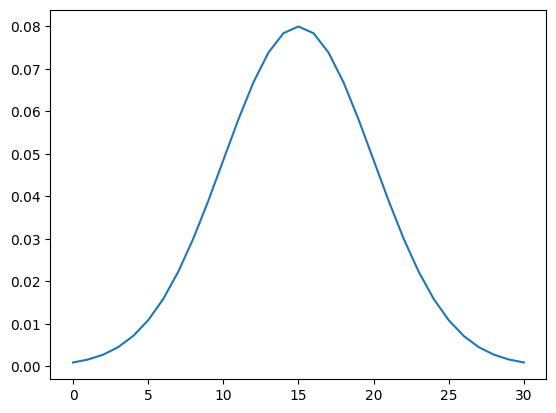

In [ ]:
sigma = 5
len = math.ceil(sigma * 3)
indices = np.arange(-len,len+1)
gausMask1D = -1.*(indices)**2/(2*sigma**2)
gausMask1D = 1/(math.sqrt(2*math.pi)*sigma)*np.exp(gausMask1D)
sum = np.sum(gausMask1D)
gausMask1D = gausMask1D/sum

plt.plot(gausMask1D)
plt.show()

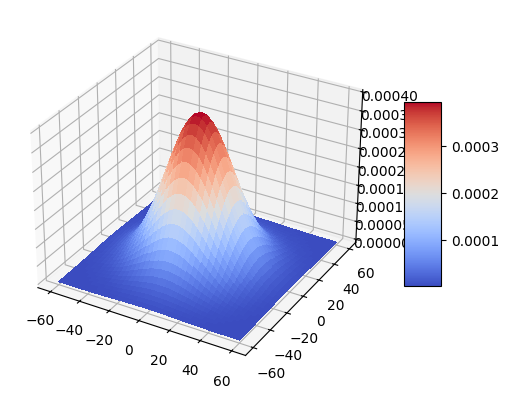

In [ ]:
sigma =20
len = math.ceil(sigma * 3)

x= np.arange(-len,len+1)
y = np.arange(-len,len+1)
X,Y = np.meshgrid(x,y)
gausMask2D = (1/(2*math.pi*sigma**2))* np.exp(-1*((X**2+Y**2)/(2*sigma**2)))

fig = plt.figure()
ax = fig.add_subplot(projection = '3d')


surf = ax.plot_surface(X,Y,gausMask2D, cmap = cm.coolwarm,linewidth=0, antialiased = False)
fig.colorbar(surf, shrink = 0.5, aspect = 5)
plt.show()


**DERIVATIVE OF GAUSIAN FILTER**

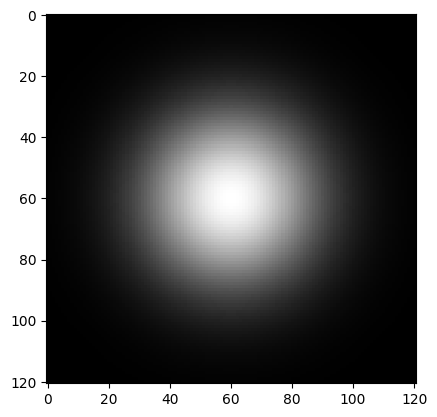

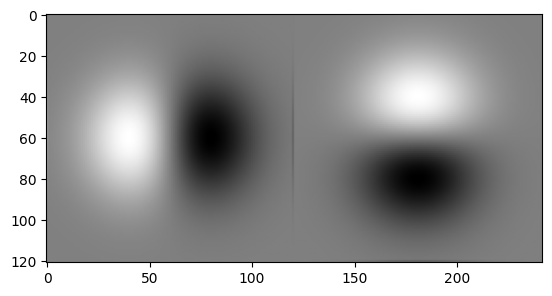

In [ ]:
sy = snd.sobel(gausMask2D, axis=0, mode='constant')
sx = snd.sobel(gausMask2D, axis=1, mode='constant')

imgplot= plt.imshow(gausMask2D, cmap='gray')
plt.show()

im_con = np.concatenate((sx,sy), axis=1)
imgplot= plt.imshow(im_con, cmap='gray')
plt.show()


GAUSIAN

-136.16996314835072
144.19034332036912


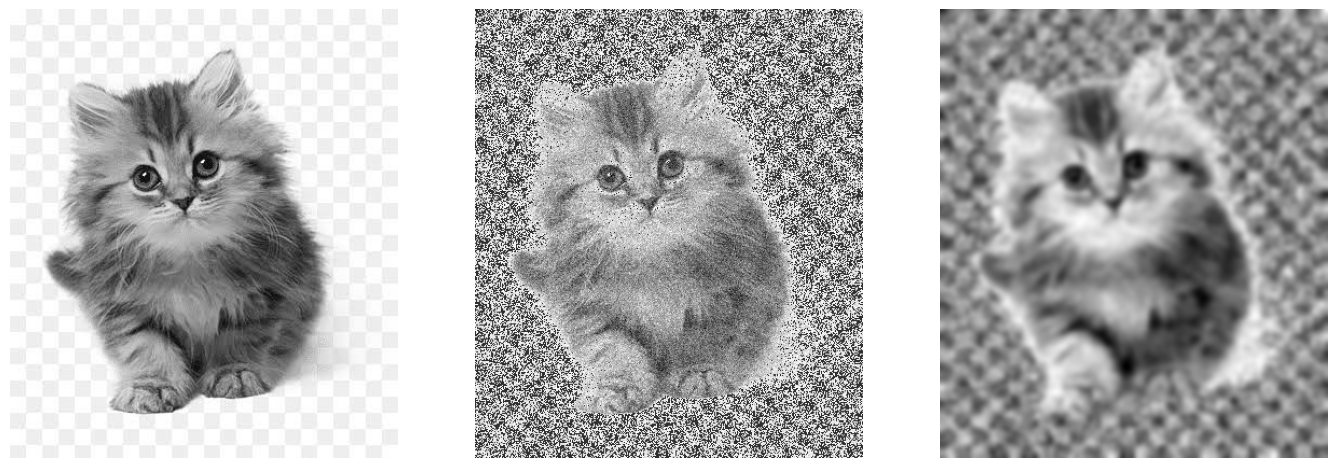

In [ ]:
dim1 = im_gray.shape[0]
dim2 =im_gray.shape[1]
noise = np.random.randn(dim1,dim2)*30+5
print(noise.min())
print(noise.max())
im_ns = np.float64(im_gray)+noise
mask= im_ns > 255
im_ns[mask] = 255
mas = im_ns < 0
im_ns[mask] = 0
im_nr =gaussian_filter(im_ns,3)

fig, ax= plt.subplots(nrows=1, ncols=3, figsize=(13,13))
ax[0].imshow(im_gray, cmap= 'gray')
ax[0].axis('off')
ax[1].imshow(im_ns, cmap= 'gray')
ax[1].axis('off')
ax[2].imshow(im_nr, cmap= 'gray')
ax[2].axis('off')

plt.show()

**SALT AND PAPER NOISE REMOVE**

8.55997940196751e-06
0.9999915856437098


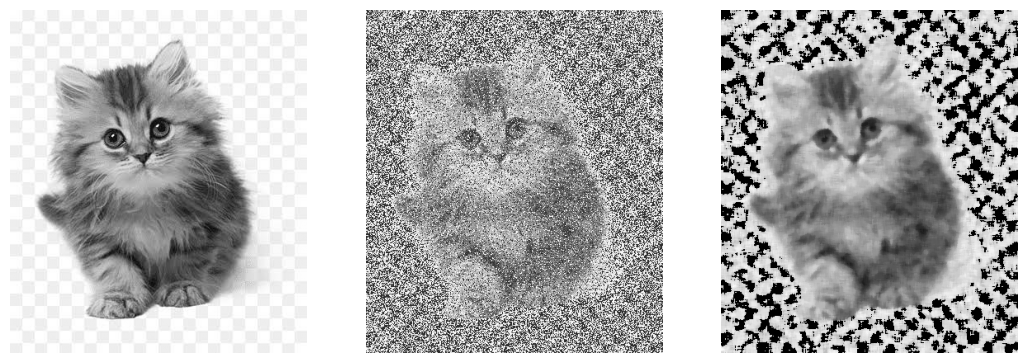

In [ ]:
temp = np.random.rand(dim1,dim2)
print(temp.min())
print(temp.max())
mask1 = temp > 0.9
mask2 = temp < 0.1
im_ns[mask1]=255
im_ns[mask2]=0

im_nr =median_filter(im_ns,7)

fig, ax= plt.subplots(nrows=1, ncols=3, figsize=(13,13))

ax[0].imshow(im_gray, cmap= 'gray')
ax[0].axis('off')
ax[1].imshow(im_ns, cmap= 'gray')
ax[1].axis('off')
ax[2].imshow(im_nr, cmap= 'gray')
ax[2].axis('off')

plt.show()


**2D GAUSSIAN FILTER**

In [ ]:
def Gauss2DMask(sigma):
  len = math.ceil(sigma * 3)
  x = np.arange(-len,len+1)
  y = np.arange(-len,len+1)
  X, Y = np.meshgrid(x,y)
  gausMask2D = (1/(2*math.pi*sigma**2))* np.exp(-1*((X**2+Y**2)/(2*sigma**2)))

  gausMask2D = gausMask2D/gausMask2D.sum()
  return gausMask2D

**NORMALIZER**

In [ ]:
def maxmin_norm(I):
  min_image = min(I.flatten())
  Inorm = I-min_image
  max_image = max(Inorm.flatten())
  Inorm = Inorm/max_image
  Inorm = Inorm * 255
  return Inorm

In [ ]:
sigma = 5;
maskG = Gauss2DMask(sigma);
maskGy = snd.sobel(maskG, axis=0, mode='constant')
maskGx = snd.sobel(maskG, axis=1, mode='constant')
maskGyy = snd.sobel(maskGy, axis=0, mode='constant')
maskGxx = snd.sobel(maskGx, axis=1, mode='constant')

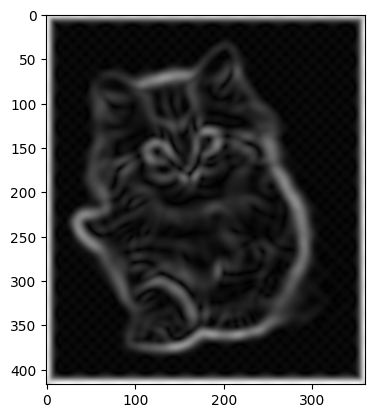

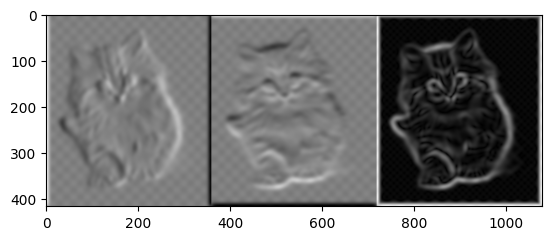

In [ ]:
im_gray_y =snd.convolve(im_gray, maskGy, mode='constant')
im_gray_x =snd.convolve(im_gray, maskGx, mode='constant')
im_grad = np.hypot(im_gray_y, im_gray_x)

imgplot= plt.imshow(im_grad, cmap='gray')
plt.show()

im_con = np.concatenate((maxmin_norm(im_gray_x),maxmin_norm(im_gray_y),maxmin_norm(im_grad)), axis=1)
imgplot = plt.imshow(im_con, cmap='gray')
plt.show()


**2D LOG FILTERS PLOTTING**

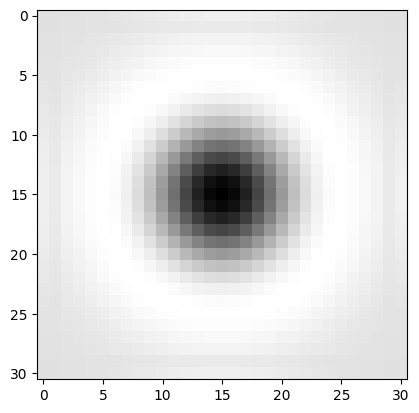

In [ ]:
LoGfilter = maxmin_norm(maskGxx+maskGyy)
imgplot = plt.imshow(LoGfilter, cmap='gray')
plt.show()

In [ ]:
def LoGfilter(sigma,infoPrint):
  len = math.ceil(sigma *3)
  x = np.arange(-len,len+1)
  y = np.arange(-len,len+1)

  X, Y = np.meshgrid(x,y)

  laplacianMask2D = (-1/(math.pi*sigma**4))* (1-(X**2+Y**2)/(2*sigma**2))*np.exp(-1*((X**2+Y**2)/(2*sigma**2)))

  if(infoPrint):
    print(np.sum(laplacianMask2D, axis = None))
    fig = plt.figure()
    ax = fig.add_subplot(projection = '3d')
    surf = ax.plot_surface(X,Y,laplacianMask2D, cmap = cm.coolwarm,linewidth=0, antialiased = False)
    ax.view_init(elev=20,azim=-10)
    ax.dist=5

    fig.colorbar(surf, shrink = 0.5, aspect = 5)
    plt.show()

    return laplacianMask2D

-0.0015994798841633554


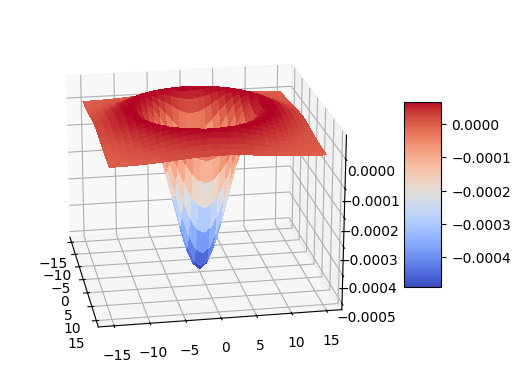

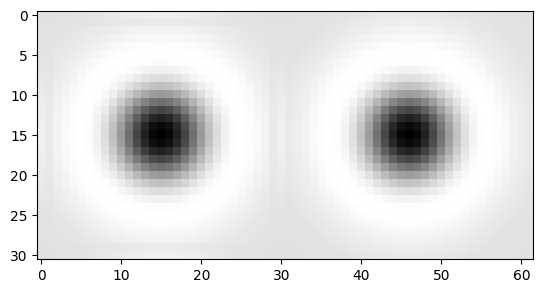

In [ ]:
sigma=5;
maskLoG = LoGfilter(sigma,True)
im_con = np.concatenate((maxmin_norm(maskGxx+maskGyy), maxmin_norm(maskLoG)), axis=1)
imgplot = plt.imshow(im_con, cmap='gray')
plt.show()

**EDGE DETECTION WITH LOG FILTERING**

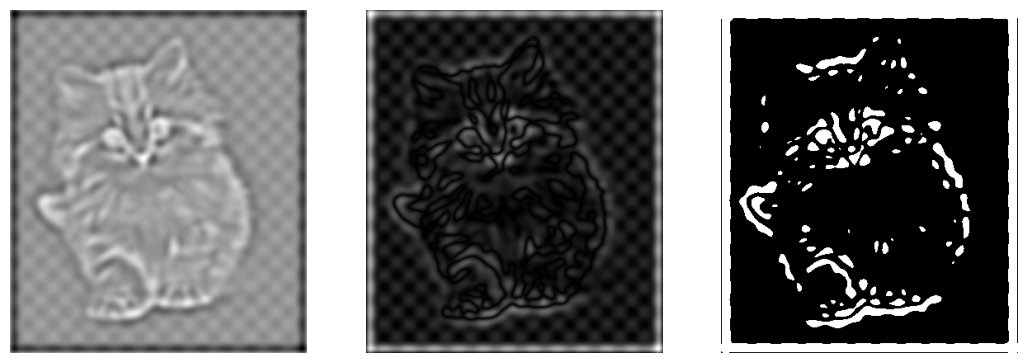

In [ ]:
im_gray_log = snd.convolve(im_gray, maskLoG, mode='constant')
maxValue = np.abs(im_gray_log).max()
edges = np.uint8(np.abs(im_gray_log) > 0.2*maxValue) *255

fig,ax = plt.subplots(nrows=1, ncols=3, figsize=(13,13))

ax[0].imshow(im_gray_log, cmap='gray')
ax[0].axis('off')
ax[1].imshow(np.abs(im_gray_log), cmap='gray')
ax[1].axis('off')
ax[2].imshow(edges, cmap='gray')
ax[2].axis('off')
plt.show()